Graph out the frequency and rythm of the steps in a long jump / triple jump approach using YOLO pose to track the athlete.

Import

In [1]:
%load_ext autoreload
%autoreload 2

import cv2
import numpy as np
from ultralytics import YOLO
import os
import pandas as pd
import matplotlib.ticker as ticker
from scipy.signal import find_peaks 
from scipy.signal import savgol_filter

from longJump import tracking

from longJump import config
import importlib
importlib.reload(config)


from longJump.config import ROOT, PATHS, DETECTION, ATHLETE, TRACKING
from longJump.video import Video
from longJump import visualization
from longJump.athlete import Athlete
from longJump import detection



Load Image / Video

In [4]:
video_path = str(ROOT / PATHS["videos"] / "coachVideoBeginner.mp4")
save_path = str(ROOT / PATHS["output"] / "coachVideoBeginnerBoundingBoxTest.mp4")
bounding_box_model_path = str(ROOT / PATHS["bounding_box_model"])
tracker_path = str(ROOT / PATHS["tracker"])


video = Video(video_path)



Run model to detect the person 

conf=0.25: Minimum confidence for detections.
iou=0.45: IoU threshold for non-maximum suppression.
classes=[0]: Detects only the “person” class (COCO ID 0).
device=’cuda:0': Uses GPU for inference.
half=True: Uses half-precision (FP16) for speed.
verbose=False: Suppresses detailed logs.

Run the pose model to identify keypoints of the person 

In [5]:

tracker_results = tracking.RunTrackingBoundingBox(bounding_box_model_path, tracker_path, video_path, conf=TRACKING["conf_track"], iou=TRACKING["iou_track"],imgsz=TRACKING["imgsz_track"])

print(tracker_results)

# bounding_boxes_df, video_keypoints_df = tracking.ProcessTrackingResults(pose_results)
bounding_boxes_df = tracking.ProcessBoundingBoxResults(tracker_results)




# video_keypoints_df = tracking.InterpolateLowConfidenceAnkles(video_keypoints_df, TRACKING["minimum_confidence_threshold"])


bounding_boxes_df

<generator object BasePredictor.stream_inference at 0x0000024492D83AC0>
WARNING 'source' is missing. Using 'source=C:\Users\ekrik\anaconda3\envs\jumpCV\Lib\site-packages\ultralytics\assets'.


,frame,person_id,x1,y1,x2,y2,conf
0,0,1,554.099243,128.433594,596.799255,209.997269,0.901855
1,0,2,395.308594,136.940216,420.661713,186.478897,0.868652
2,0,3,795.287476,129.767975,812.634338,185.144531,0.690918
3,0,4,779.275024,133.854492,796.621887,192.316803,0.675781
4,0,5,2.230908,138.775009,15.220215,174.469528,0.672363
...,...,...,...,...,...,...,...
1989,217,109,397.938934,152.965820,411.050476,195.166397,0.827637
1990,217,120,787.278259,131.365616,796.685669,161.678513,0.381104
1991,217,114,805.806213,133.625092,823.523865,172.094437,0.640625
1992,217,110,795.308289,130.729553,807.329956,170.336655,0.565918


In [ ]:
import pprint


athlete_id = -1

bounding_boxes_df = bounding_boxes_df.sort_values(by=["person_id", "frame"]) # sort by frame and person_id

bounding_boxes_df["area"] = (bounding_boxes_df["x2"] - bounding_boxes_df["x1"]).abs() * (bounding_boxes_df["y2"] - bounding_boxes_df["y1"]).abs()



person_stats = {}

# for pid in bounding_boxes_df["person_id"].unique():
#     person_df = bounding_boxes_df.loc[bounding_boxes_df["person_id"] == pid]
#     if (len(person_df) > 30): # Person appears for more than 30 frames
#         person_stats[pid] = {}
#         person_stats[pid]["total_area"] = person_df["area"].sum()
#         person_stats[pid]["total_movement"] = abs(person_df["area"].diff().sum())

# pprint.pprint(person_stats)

# previous_area = 0
# for pid in person_stats.keys():
#     if (person_stats[pid]["total_area"] > previous_area):
#         athlete_id = pid
#         previous_area = person_stats[pid]["total_area"]

# print(athlete_id)

{np.int64(1): {'total_area': np.float32(778598.44),
               'total_movement': np.float32(5125.9746)},
 np.int64(2): {'total_area': np.float32(44938.816),
               'total_movement': np.float32(56.72693)},
 np.int64(5): {'total_area': np.float32(19757.094),
               'total_movement': np.float32(64.32709)},
 np.int64(7): {'total_area': np.float32(14609.265),
               'total_movement': np.float32(15.546173)},
 np.int64(12): {'total_area': np.float32(16117.15),
                'total_movement': np.float32(33.07785)},
 np.int64(16): {'total_area': np.float32(12495.564),
                'total_movement': np.float32(75.31036)},
 np.int64(18): {'total_area': np.float32(7081.8057),
                'total_movement': np.float32(118.204346)},
 np.int64(30): {'total_area': np.float32(26030.768),
                'total_movement': np.float32(108.46521)},
 np.int64(41): {'total_area': np.float32(9825.717),
                'total_movement': np.float32(76.55829)},
 np.int64(50): 

In [16]:



def processVideo(cap, video, save_path, bounding_boxes_df, athlete_id):

    fps = video.fps
    width = video.width
    height = video.height

    output = cv2.VideoWriter(
        save_path, cv2.VideoWriter_fourcc(*'mp4v'), 
        fps, (width, height))
    
    frame_num = 0
    
    while(True):
        ret, frame = cap.read() # ret is if frame is sucesfully captured

        
        if(ret):

            cv2.putText(frame, "Frame: " + str(frame_num), (20, 30), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 3)    
            processBoundingBoxes(frame=frame, frame_num=frame_num, bounding_boxes_df=bounding_boxes_df, width=int(width/280), athlete_id=athlete_id)


            output.write(frame)

            
        else:
            break

        frame_num += 1


    cv2.destroyAllWindows()
    output.release()
    

def processBoundingBoxes(frame, frame_num, bounding_boxes_df, width, athlete_id):
    
    frame_df  = bounding_boxes_df.loc[bounding_boxes_df['frame'] == frame_num]
        
        
    # Convert just the coordinate columns straight to a NumPy array.
    people = frame_df[["x1", "y1", "x2", "y2", "person_id"]].to_numpy().astype(int)
    conf = frame_df["conf"].to_numpy().astype(float)

    for person_num, person in enumerate(people):

        color = (0, 0, 255) if person[4] == athlete_id else (0, 255, 0)

        
        
    
        cv2.rectangle(frame, (person[0], person[1]), (person[2], person[3]),
                    color, width)
        cv2.putText(frame, "Person " + str(person[4]) + ". Conf: " + str(conf[0]), (person[0], person[1] - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 3)
        


if (video == None):
    video = Video(video_path)



with video as cap:
    processVideo(cap, video, save_path, bounding_boxes_df, athlete_id)

# athlete_id = input("Which person id is the athlete? ")


In [ ]:
from IPython.display import Image



In [28]:
athlete_id = int(input("Which person id is the athlete? "))

athlete_id

1

1


,frame,person_id,left_x,left_y,right_x,right_y,left_hip_x,left_hip_y,right_hip_x,right_hip_y,left_knee_x,left_knee_y,right_knee_x,right_knee_y,left_conf,right_conf,left_hip_conf,right_hip_conf,left_knee_conf,right_knee_conf
0,0,1,1461.000,561.00,1440.000,561.00,1461.000,502.00,1445.000,501.00,1461.0,531.50,1443.000,530.00,0.990723,0.990234,0.997070,0.996094,0.997070,0.997070
2,1,1,1461.000,561.50,1440.000,562.00,1461.000,503.00,1445.000,502.00,1461.0,532.50,1443.000,531.50,0.989746,0.989258,0.997070,0.996094,0.996582,0.996582
3,2,1,1461.000,564.00,1441.000,563.50,1461.000,504.25,1445.000,503.50,1461.0,534.00,1443.000,532.50,0.988770,0.989258,0.996582,0.996094,0.996094,0.996582
4,3,1,1460.000,564.00,1440.000,564.50,1459.000,505.50,1444.000,504.50,1460.0,534.50,1442.000,533.50,0.988281,0.988770,0.997070,0.996094,0.996094,0.996582
5,4,1,1460.000,565.00,1440.000,566.00,1459.000,506.75,1443.000,505.75,1460.0,536.00,1442.000,535.00,0.988770,0.989746,0.997070,0.996582,0.996582,0.997070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
556,297,17,157.750,468.00,235.500,455.25,184.500,384.75,181.875,385.25,159.5,419.75,202.875,422.00,0.983398,0.984375,0.995117,0.981445,0.993164,0.981445
562,298,17,158.125,469.25,237.000,452.00,184.375,383.50,181.375,383.50,162.0,421.25,199.250,423.00,0.979004,0.988770,0.995117,0.986816,0.992188,0.986816
568,299,17,162.250,467.00,229.750,448.25,183.500,383.00,175.875,383.50,162.5,420.25,190.750,423.50,0.966797,0.967285,0.993164,0.982910,0.986328,0.963379
573,300,17,169.625,471.25,224.875,443.25,181.000,385.25,174.125,384.25,162.0,424.00,189.000,423.75,0.970215,0.968262,0.996094,0.985840,0.992676,0.972656


Steps to determining initial ground contact

1. Find maximum extension: Graphing when the leg is fully extended (when x position of ankle - x position of hip is at it's highest)
2. Loop through the next 30 frames
3. Find maximum vertical gradient change (the biggest negative difference in y_velocity of the ankle compared to the hip. If the ankle is going down to the ground at 15 pixels per frame, the drop from 15 to 0 as the foot hiuts the ground will be that moment, but the difference from foot striking the ground to the foot staying on the ground, 0 to 0, will not be the initial contact moment)



So, steps to achieve this

get x position of left ankle - x position of left hip

get y position of left ankle - y position of left hip

get x position of right ankle - x position of right hip

get y position of right ankle - y position of right hip



Normalize them according to maximum ankle and minimum ankle positions relative to the hip of a rolling window.



Graph the x position of the ankles and find moments of peak extension. 

Filter peaks that aren't the athlete sprinting

Look at the following frames for moments of peak deacceleratin 





Direction: Right-to-Left (Score: -0.500)
8 30 3
8 30 3


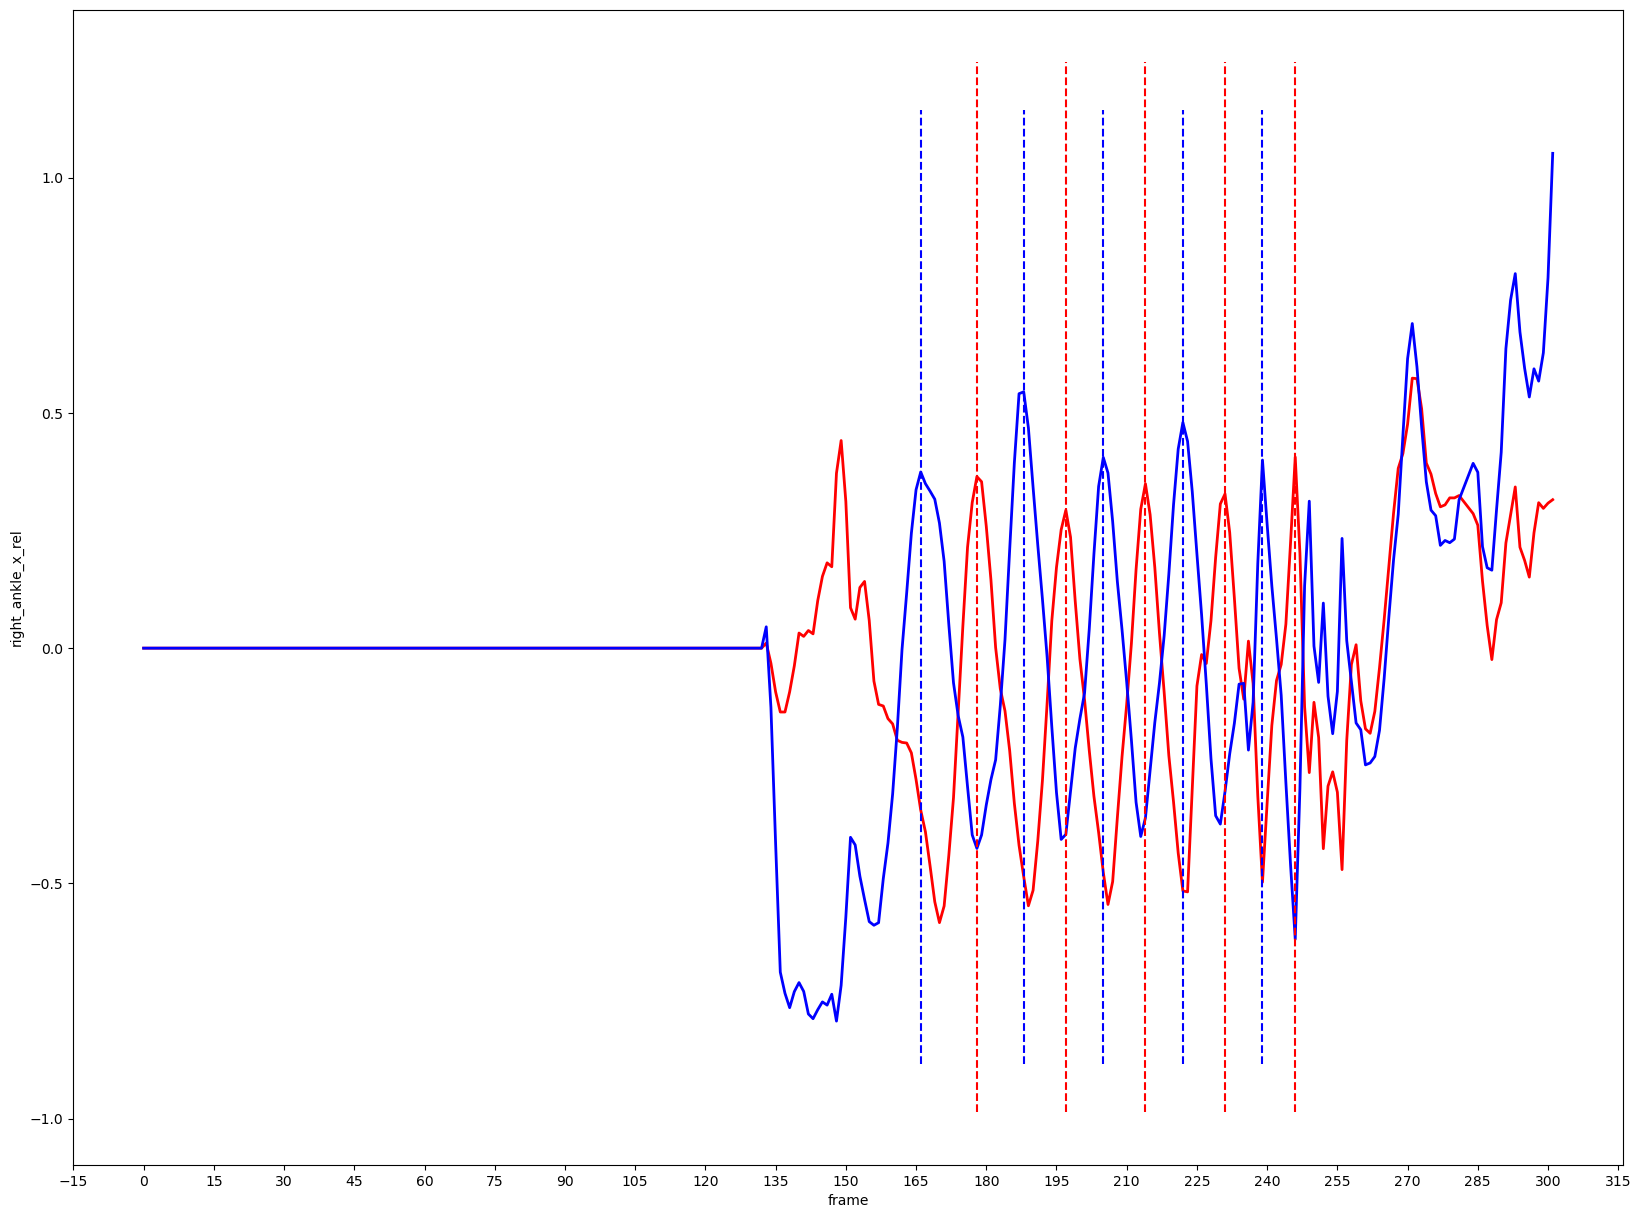

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline


athlete = Athlete(bounding_boxes_df, video_keypoints_df, athlete_id, DETECTION["minimum_movement_threshold"], video.fps)

direction_score = athlete.CalculateDirectionScore(ATHLETE["knee_peaks_prominence"], ATHLETE["minimum_direction_score"])

runningLeftToRight = True


# 4. Make the final directional decision
if direction_score > 0:
    runningLeftToRight = True
    print(f"Direction: Left-to-Right (Score: {direction_score:.3f})")
else:
    runningLeftToRight = False
    print(f"Direction: Right-to-Left (Score: {direction_score:.3f})")


if (not runningLeftToRight):
    athlete.df["left_ankle_x_rel"] *= -1
    athlete.df["right_ankle_x_rel"] *= -1




sprint_peaks_left, sprint_peaks_right = athlete.findPeaks(DETECTION["leg_extension_peak_prominence"], DETECTION["leg_extension_peak_height"], DETECTION["leg_extension_min_gap"], DETECTION["leg_extension_max_gap"], DETECTION["consecutive_extension_peak"])

# print(sprint_peaks_left, sprint_peaks_right)
# print(type(sprint_peaks_left))

plt.figure(figsize=(20, 15))  




relativeXankle = sns.lineplot(data=athlete.df, x="frame", y="right_ankle_x_rel", color="red", linewidth=2)
relativeXankle = sns.lineplot(data=athlete.df, x="frame", y="left_ankle_x_rel", color="blue", linewidth=2)

plt.vlines(sprint_peaks_left, plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="dashed")
plt.vlines(sprint_peaks_right, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")

sprint_peaks = np.concatenate((np.array(sprint_peaks_left), np.array(sprint_peaks_right)))
sprint_peaks.sort()

relativeXankle.xaxis.set_major_locator(ticker.MultipleLocator(15))
plt.show()



     left_hip_x  right_hip_x  left_hip_y  right_hip_y  left_x  right_x  \
0        1461.0       1445.0      502.00       501.00  1461.0   1440.0   
1        1461.0       1445.0      503.00       502.00  1461.0   1440.0   
2        1461.0       1445.0      504.25       503.50  1461.0   1441.0   
3        1459.0       1444.0      505.50       504.50  1460.0   1440.0   
4        1459.0       1443.0      506.75       505.75  1460.0   1440.0   
..          ...          ...         ...          ...     ...      ...   
295       771.0        793.0      700.00       677.50   738.5    776.0   
296       783.0        810.5      706.50       680.50   751.0    791.5   
297       790.5        824.0      705.50       677.50   763.0    800.5   
298       796.0        825.0      702.00       677.50   772.0    813.0   
299       812.0        846.5      707.00       680.50   784.5    829.0   

     left_y  right_y  left_knee_x  left_knee_y  ...  hip_center_x  \
0     561.0    561.0       1461.0        5

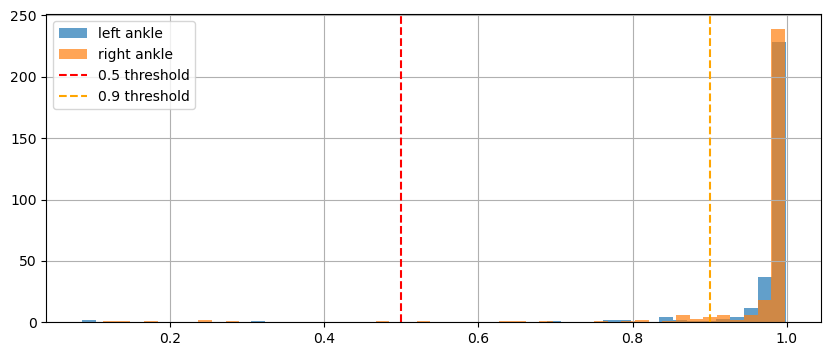

In [22]:
print(athlete.df)

plt.figure(figsize=(10, 4))
athlete.df["left_conf"].hist(bins=50, alpha=0.7, label="left ankle")
athlete.df["right_conf"].hist(bins=50, alpha=0.7, label="right ankle")
plt.axvline(0.5, color='red', linestyle='--', label='0.5 threshold')
plt.axvline(0.9, color='orange', linestyle='--', label='0.9 threshold')
plt.legend()
plt.show()

Find initial contact frames using maximum extension frames

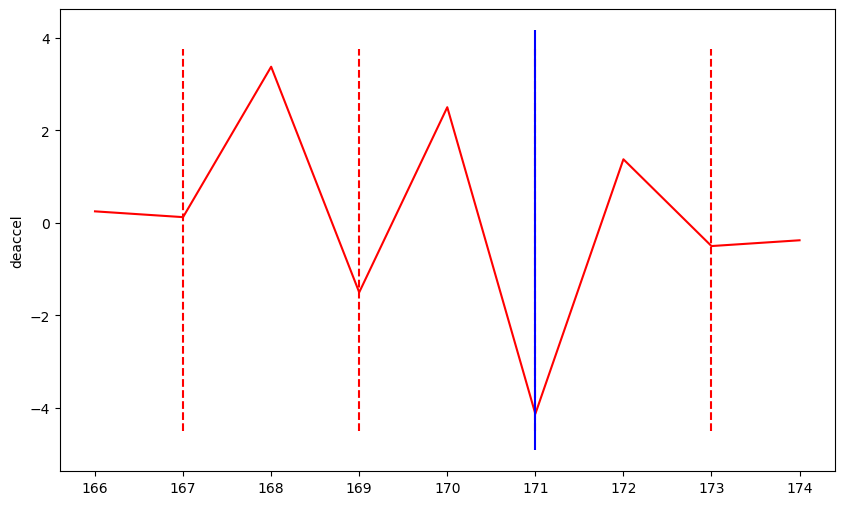

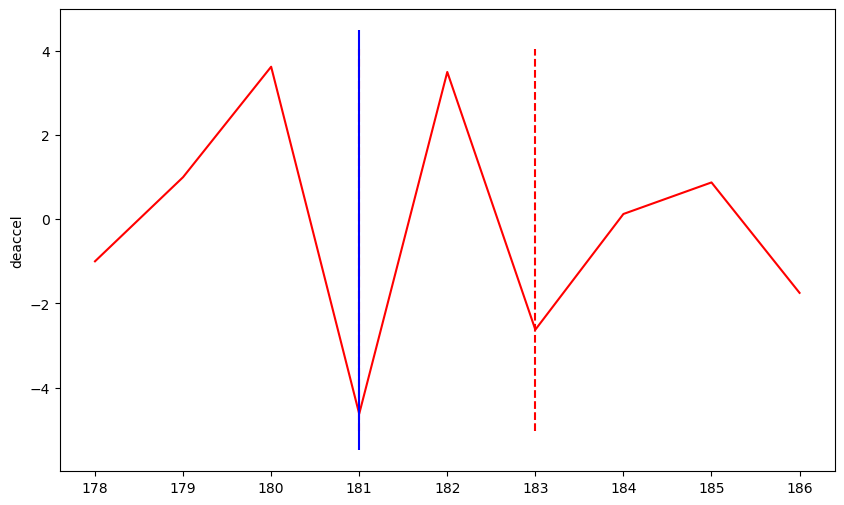

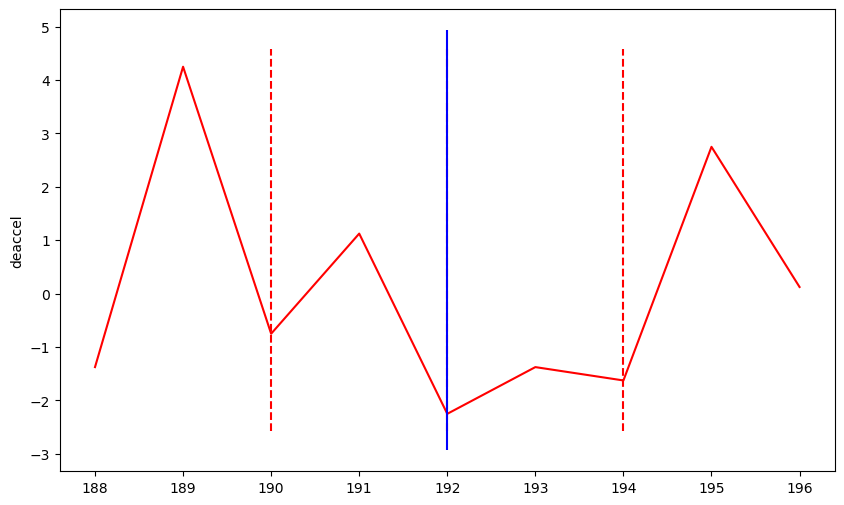

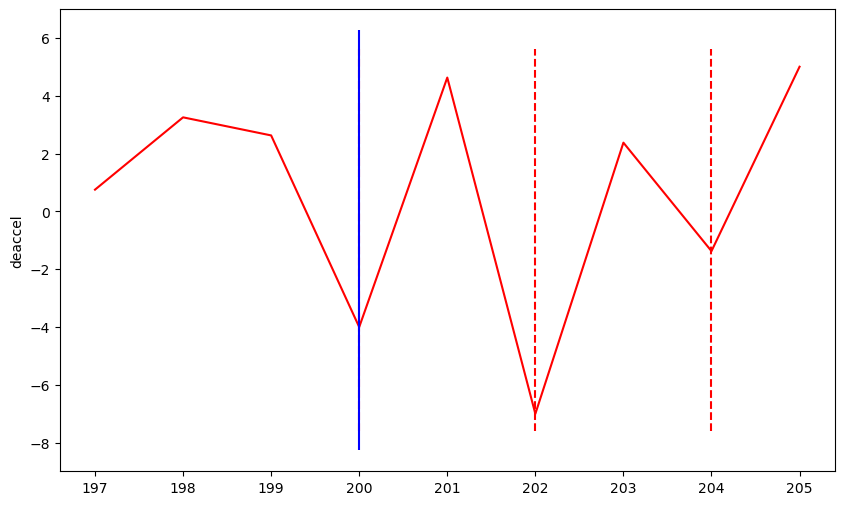

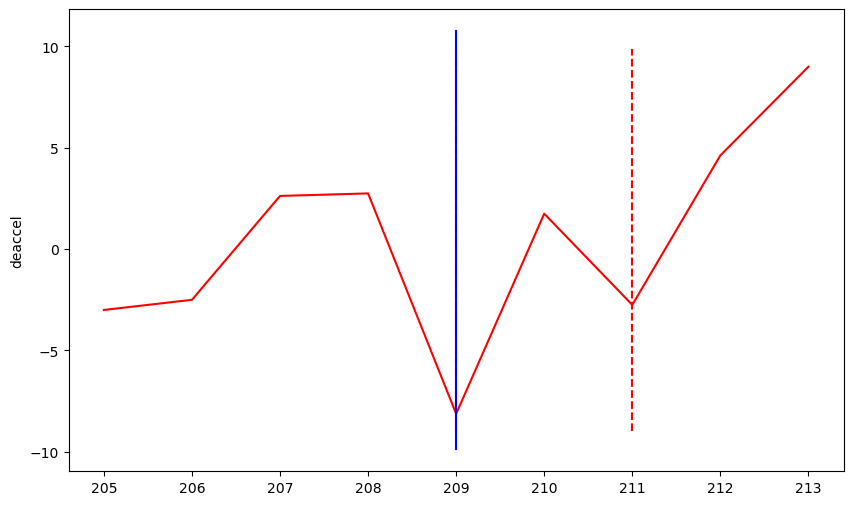

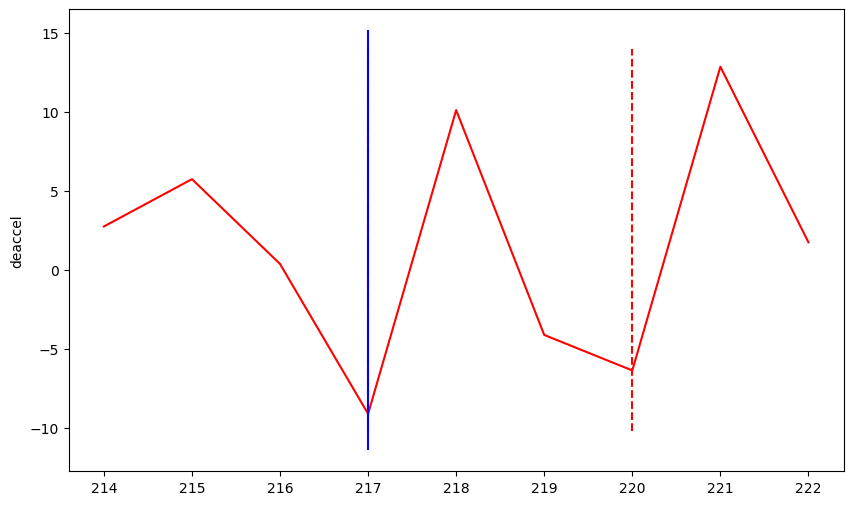

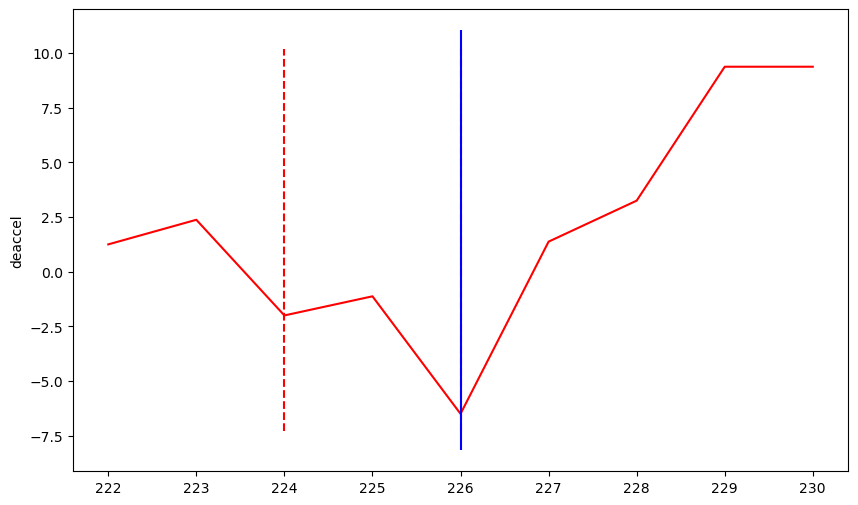

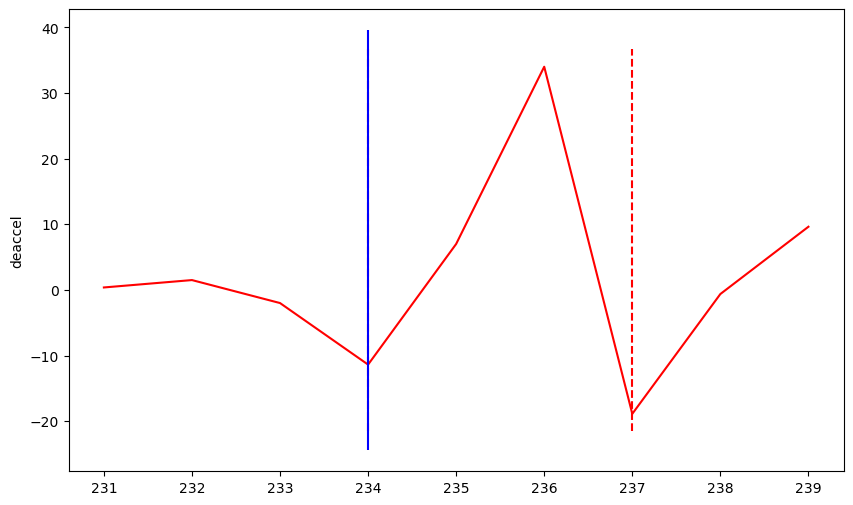

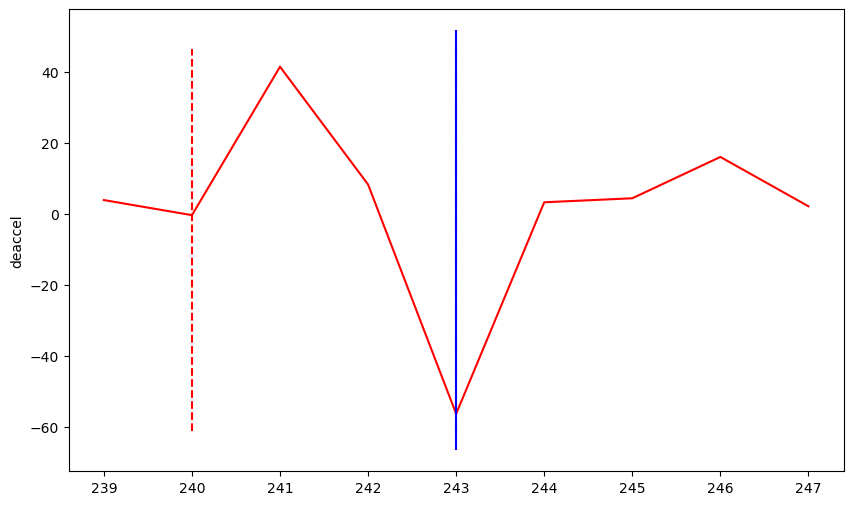

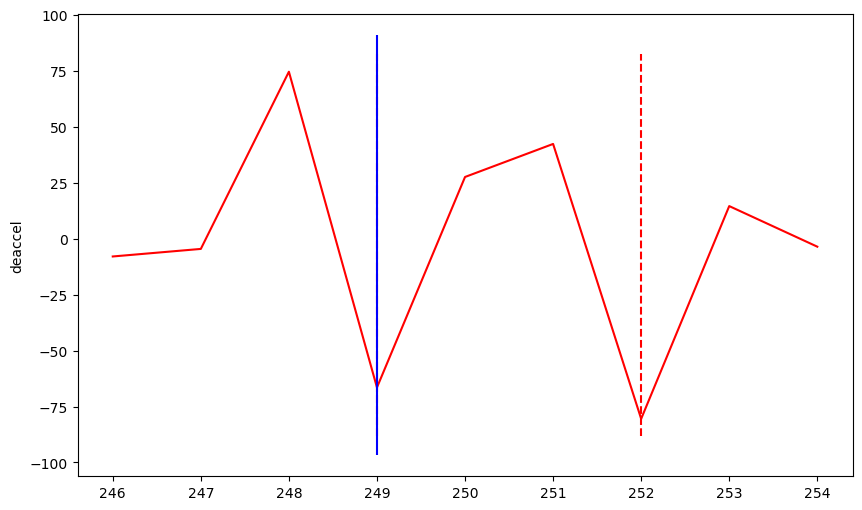

[np.int64(171), np.int64(181), np.int64(192), np.int64(200), np.int64(209), np.int64(217), np.int64(226), np.int64(234), np.int64(243), np.int64(249)]


In [23]:

frames_before_max_extension = int(DETECTION["possible_initial_contact_frames_before_leg_extension"])
frames_after_max_extension = int(round(video.fps * DETECTION["possible_initial_contact_frames_after_leg_extension"]))
initial_contact_frames = []

for max_extension_frame in sprint_peaks:
    isLeft = False
    if (max_extension_frame in sprint_peaks_left):
        isLeft = True
    ankle_df = athlete.GetAnkleVerticalDeacceleration(max_extension_frame, isLeft, frames_before_max_extension, frames_after_max_extension)

    plt.figure(figsize=(10, 6))

    sns.lineplot(ankle_df["deaccel"], color="red")

    peak_deaccel = find_peaks((ankle_df["deaccel"]) * -1)[0]

    detected_frames = ankle_df["frame"].iloc[peak_deaccel].values

    if (len(detected_frames) <= 0):
        raise detection.InitialContactNotFound()
    else:
        candidate_rows = ankle_df[ankle_df["frame"].isin(detected_frames)]

        best_row_idx = candidate_rows["x_dist"].idxmin()

        chosen_frame = candidate_rows.loc[best_row_idx, "frame"]
        initial_contact_frames.append(chosen_frame)

    plt.vlines(detected_frames, plt.ylim()[0], plt.ylim()[1], color="red", linestyles="dashed")
    plt.vlines(initial_contact_frames[-1], plt.ylim()[0], plt.ylim()[1], color="blue", linestyles="solid")
    plt.show()
    
print(initial_contact_frames)


Draw bounding boxes and circles on ankles (FOR TESTING)

Draw boxes on the bounding boxes (TESTING)

For each box:
Draws a green rectangle (cv2.rectangle) around the person.
Adds a green “Person” label above the box using cv2.putText.

In [24]:
# print(video_keypoints_df)

if (video == None):
    video = Video(video_path)

with video as cap:
    visualization.processVideo(cap, video, save_path, bounding_boxes_df, video_keypoints_df, athlete_id, initial_contact_frames, sprint_peaks, sprint_peaks_left)


Save output in save_path

In [25]:
print(f"Output image saved to {save_path}")

Output image saved to d:\Users\ekrik\Codes\JumpAproachGraphed\SavedJumpVideos\video.mp4
